In [89]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from data import load_data, get_minibatch
from utils import check_norm, plot_distribution, check_minibatch_len
from grad_check import grad_check
from layers import SoftmaxCrossEntropy, Conv2d, ReLU, MaxPool2d, Dense, GlobalAvgPool, Flatten, MaxPool2d_naive
from model import Sequential
from optimizers import SGD
from evaluation import compare_models, plot_history

data_train_path = Path('../data/fashion-mnist_train.csv')
data_test_path = Path('../data/fashion-mnist_test.csv')

labels_dict = {0: 'T-shirt/top', 1: 'Trousers', 2: 'Pullover', 
               3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 
               7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

rng = np.random.default_rng(seed=123)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


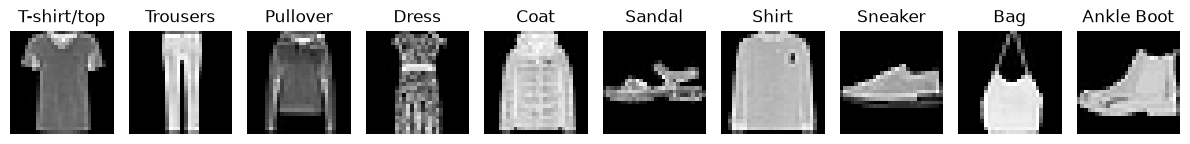

In [3]:

X_train, X_dev, X_test, Y_train, Y_dev, Y_test = load_data(data_train_path, data_test_path, dtype='float64')
labels = np.argmax(Y_train, axis=1)
classes, idx = np.unique(labels, return_index=True)

fig, ax = plt.subplots(1, 10, figsize=(12, 8))


for i in range(10):
    ax[i].imshow(X_train[idx[i]], cmap='gray')
    ax[i].axis('off')
    ax[i].set_title(labels_dict[classes[i]])

plt.tight_layout()
plt.show()



In [4]:
check_norm(X_train)

mean: 0.0, std: 1.0


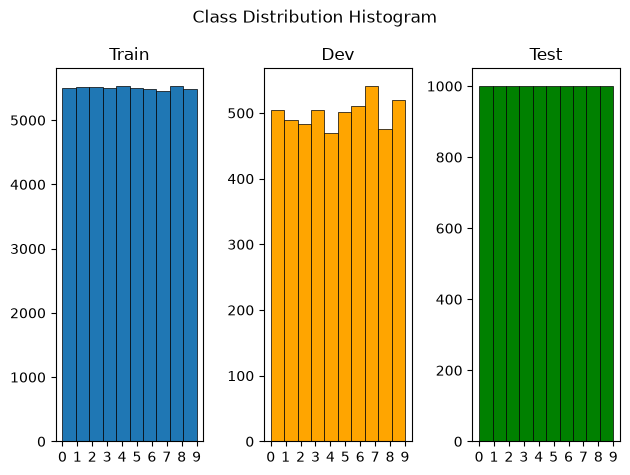

In [5]:
fig, ax = plt.subplots(1, 3)
fig.suptitle('Class Distribution Histogram')
plot_distribution(Y_train, Y_dev, Y_test, ax)
plt.tight_layout()
plt.show()

In [6]:
m = len(X_train)
minibatch_loader = get_minibatch(X_train, Y_train, size=64)
check_minibatch_len(minibatch_loader, m)

All tests passed


In [ ]:
Model_CNN = Sequential([
    Conv2d(8, f=3, s=1, p='same'), 
    ReLU(), 
    MaxPool2d(), 
    Conv2d(16, f=3, s=1, p='same'), 
    ReLU(), 
    MaxPool2d(), 
    Flatten(), 
    Dense(64),
    ReLU(),
    Dense(10)], 
    input_shape=(28, 28, 1), rng=rng)

Model_CNN.build()

In [ ]:
CNN_output = Model_CNN.fit(SoftmaxCrossEntropy(), X_train, Y_train, X_dev, Y_dev, 
              optimizer=SGD, max_epochs=100, batch_size=64, lr=1e-4, 
              return_=['all'],  print_time=True)

Epoch: 0, loss: 2.253671, accuracy train: 0.622, accuracy dev: 0.622
Time per epoch: 0.207 min 
Average time per minibatch: 0.0108 s

Epoch: 1, loss: 1.568763, accuracy train: 0.676, accuracy dev: 0.678
Time per epoch: 0.208 min 
Average time per minibatch: 0.0108 s

Epoch: 2, loss: 1.243909, accuracy train: 0.706, accuracy dev: 0.707
Time per epoch: 0.206 min 
Average time per minibatch: 0.0108 s

Epoch: 3, loss: 1.0711, accuracy train: 0.72, accuracy dev: 0.722
Time per epoch: 0.223 min 
Average time per minibatch: 0.0115 s

Epoch: 4, loss: 0.958486, accuracy train: 0.722, accuracy dev: 0.728
Time per epoch: 0.22 min 
Average time per minibatch: 0.0115 s

Epoch: 5, loss: 0.870698, accuracy train: 0.739, accuracy dev: 0.74
Time per epoch: 0.207 min 
Average time per minibatch: 0.0109 s

Epoch: 6, loss: 0.815346, accuracy train: 0.742, accuracy dev: 0.742
Time per epoch: 0.203 min 
Average time per minibatch: 0.0105 s

Epoch: 7, loss: 0.76223, accuracy train: 0.755, accuracy dev: 0.757

In [111]:
Model_CNN.evaluate(SoftmaxCrossEntropy(), X_dev, Y_dev)

(np.float64(0.4907113687010586), np.float64(0.8264))

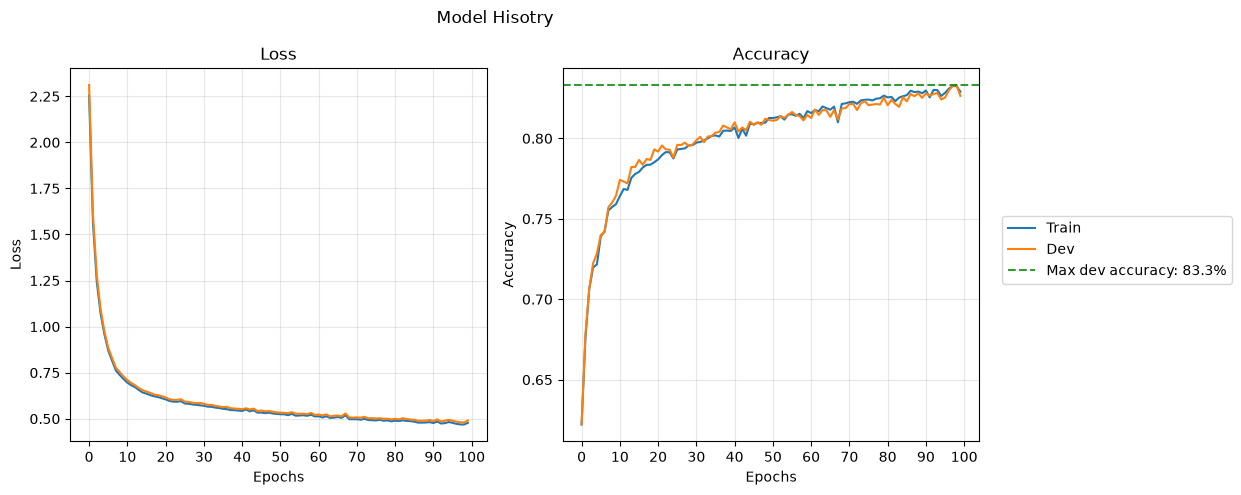

In [122]:
plot_history(CNN_output)